# Person 4: best-practices perturbation analysis

This notebook asks: **which perturbations affect which biological endpoints, how large are the effects, and at what stage of the dynamics do they act?**

The analysis does not rely on a single phase diagram. It combines:

1. global parameter–endpoint associations
2. nonlinear binned response curves
3. standardized regression and interaction terms
4. endpoint tradeoff plots
5. representative ODE time courses
6. explicit treatment of nonconvergence and collapse

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from dataclasses import replace
from scipy.stats import spearmanr
from sklearn.preprocessing import StandardScaler

from ma2024_model import DEFAULT_PARAMS
from sweep_engine import simulate_logspace

sns.set_theme(style='whitegrid', context='notebook')
df = pd.read_csv('treatment_grid.csv')
PARAMS = ['kappa_b', 'd_a', 'phi_max', 'xi']
LABELS = {'kappa_b':'κ_b', 'd_a':'d_a', 'phi_max':'φ_max', 'xi':'ξ'}
BASELINE = {'kappa_b':0.35, 'd_a':0.02, 'phi_max':1.0, 'xi':0.8}

# Derived biological quantities
df['total_final'] = df['ns_final'] + df['nr_final']
df['total_initial'] = 0.4
df['community_ratio_R_to_S'] = df['nr_final'] / df['ns_final'].replace(0, np.nan)
df['nonconverged'] = ~df['ss_converged']
df['collapsed'] = df['total_final'] < 1e-6

OUTCOMES = ['diversity_final','t_steady_state','f_R_final','t_recovery_S','peak_loss_total','total_final','ns_final','nr_final']
OUTCOME_LABELS = {'diversity_final':'Final diversity','t_steady_state':'Steady-state time','f_R_final':'Final resistant fraction','t_recovery_S':'S recovery time','peak_loss_total':'Peak total loss','total_final':'Final total population','ns_final':'Final S population','nr_final':'Final R population'}
print(df.shape)
print('Nonconverged:', df['nonconverged'].sum())
print('Collapsed:', df['collapsed'].sum())

(194481, 21)
Nonconverged: 462
Collapsed: 282


## 1. Start with global effect sizes

Because the parameters were swept independently, parameter–parameter correlations are not the main question. The important question is how each parameter changes each endpoint across the whole parameter space.

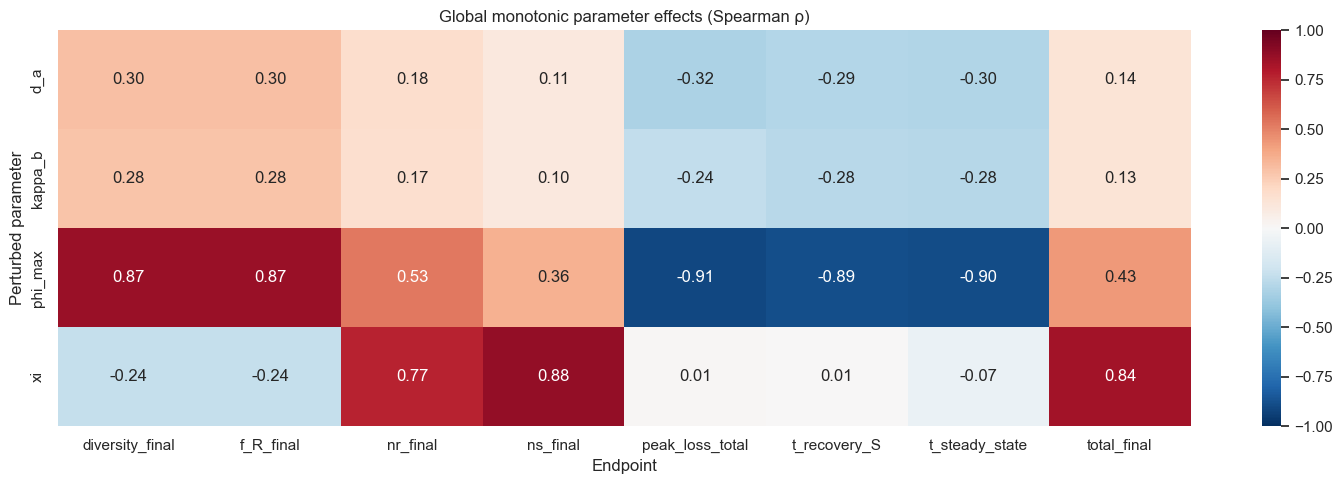

,parameter,outcome,rho,p_value,abs_rho
20,phi_max,peak_loss_total,-0.910451,0.0,0.910451
17,phi_max,t_steady_state,-0.896058,0.0,0.896058
19,phi_max,t_recovery_S,-0.886596,0.0,0.886596
30,xi,ns_final,0.876016,0.0,0.876016
16,phi_max,diversity_final,0.865361,0.0,0.865361
18,phi_max,f_R_final,0.865361,0.0,0.865361
29,xi,total_final,0.836985,0.0,0.836985
31,xi,nr_final,0.772461,0.0,0.772461
23,phi_max,nr_final,0.529284,0.0,0.529284
21,phi_max,total_final,0.433132,0.0,0.433132


In [2]:
effect_rows = []
for parameter in PARAMS:
    for outcome in OUTCOMES:
        valid = df[[parameter, outcome]].dropna()
        rho, p_value = spearmanr(valid[parameter], valid[outcome])
        effect_rows.append({'parameter':parameter,'outcome':outcome,'rho':rho,'p_value':p_value,'abs_rho':abs(rho)})
effects = pd.DataFrame(effect_rows)

effect_matrix = effects.pivot(index='parameter', columns='outcome', values='rho')
plt.figure(figsize=(15,5))
sns.heatmap(effect_matrix, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1)
plt.title('Global monotonic parameter effects (Spearman ρ)')
plt.xlabel('Endpoint'); plt.ylabel('Perturbed parameter')
plt.tight_layout(); plt.show()
display(effects.sort_values('abs_rho', ascending=False).head(15))

## 2. Nonlinear marginal effects

A simple correlation can miss thresholds or saturation. These plots divide each parameter into quantile bins and show the average endpoint across the entire remaining parameter space.

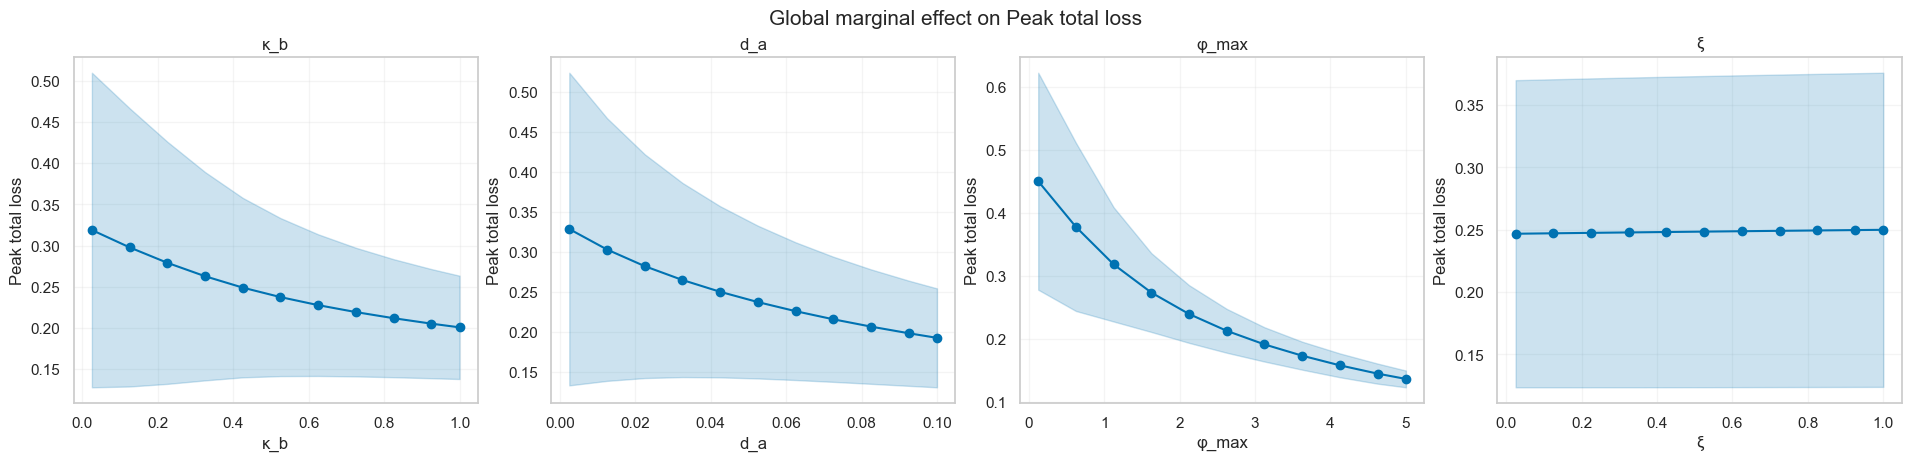

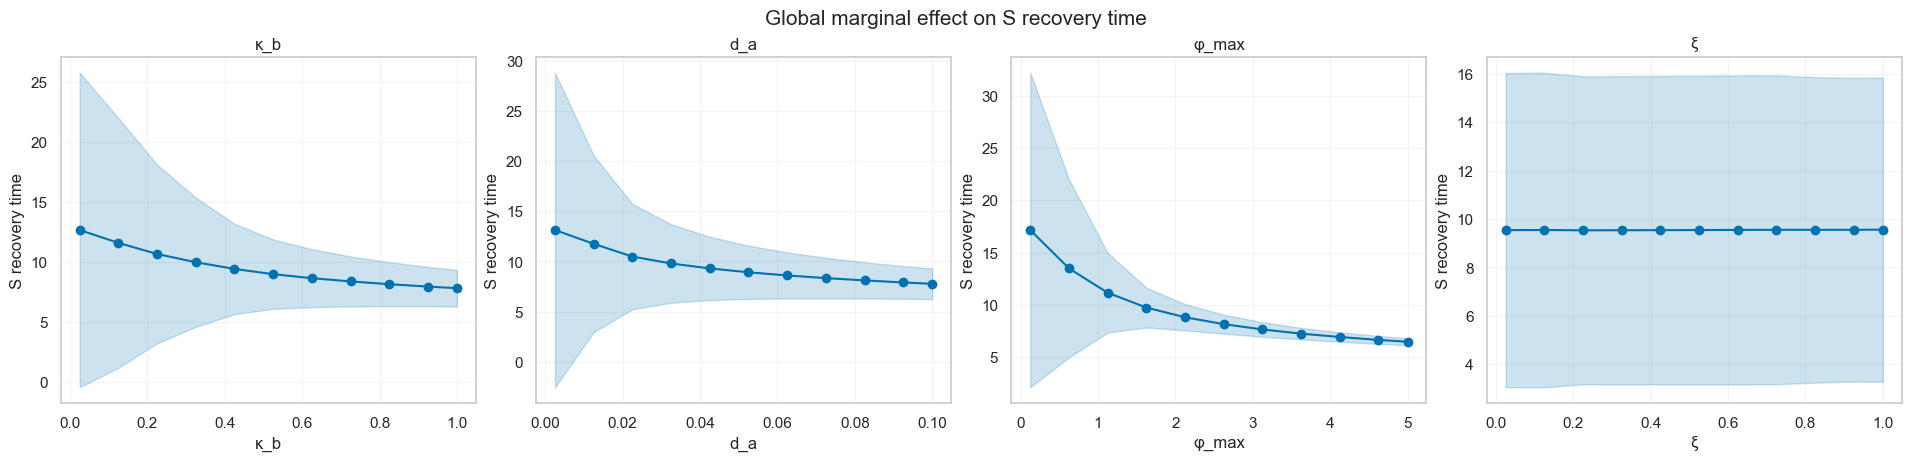

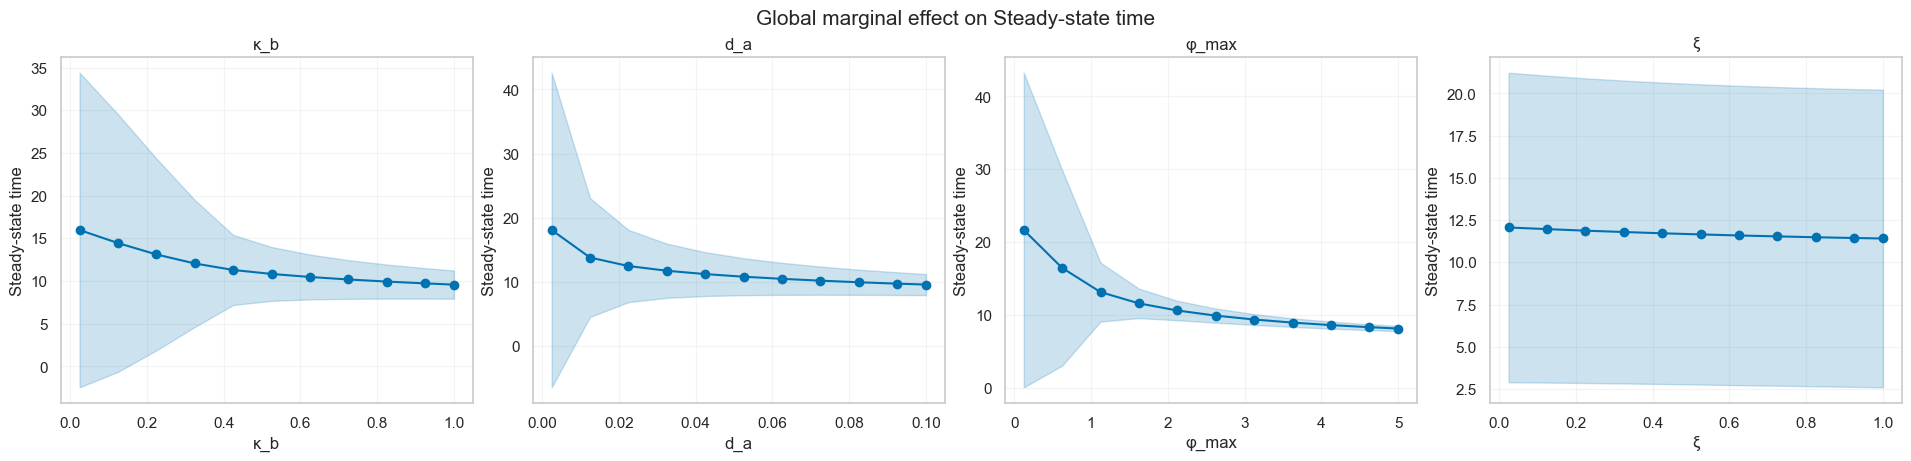

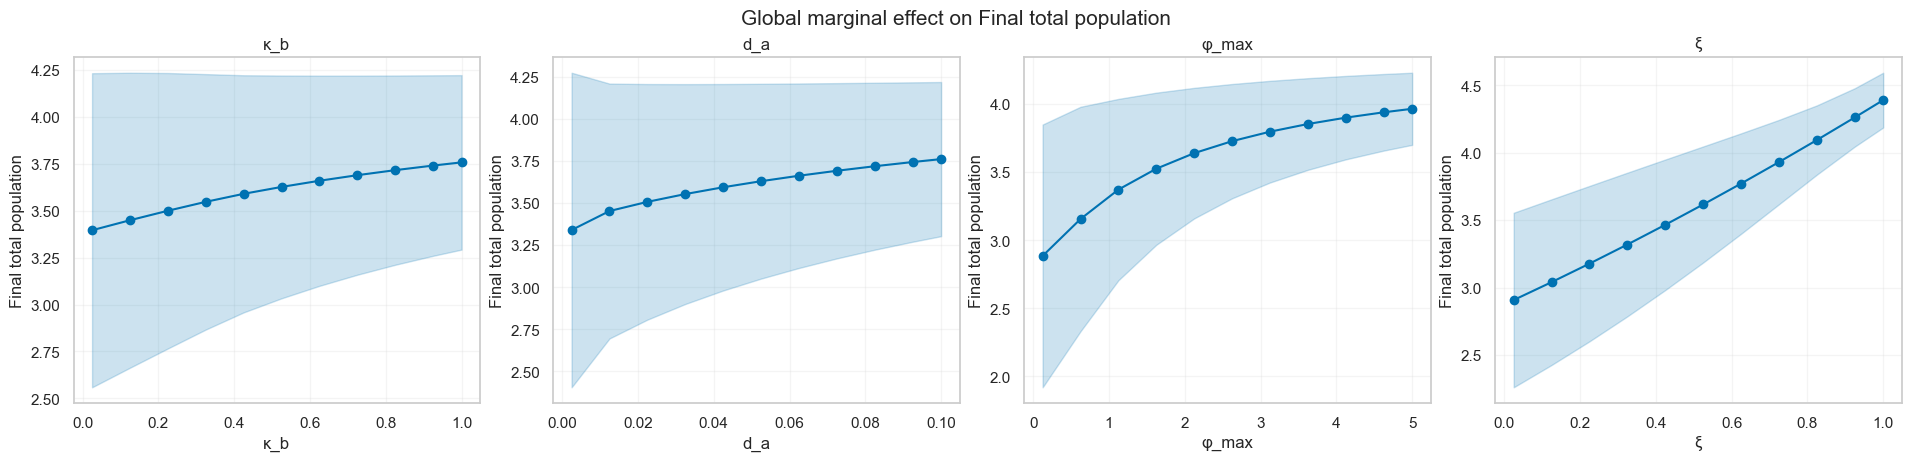

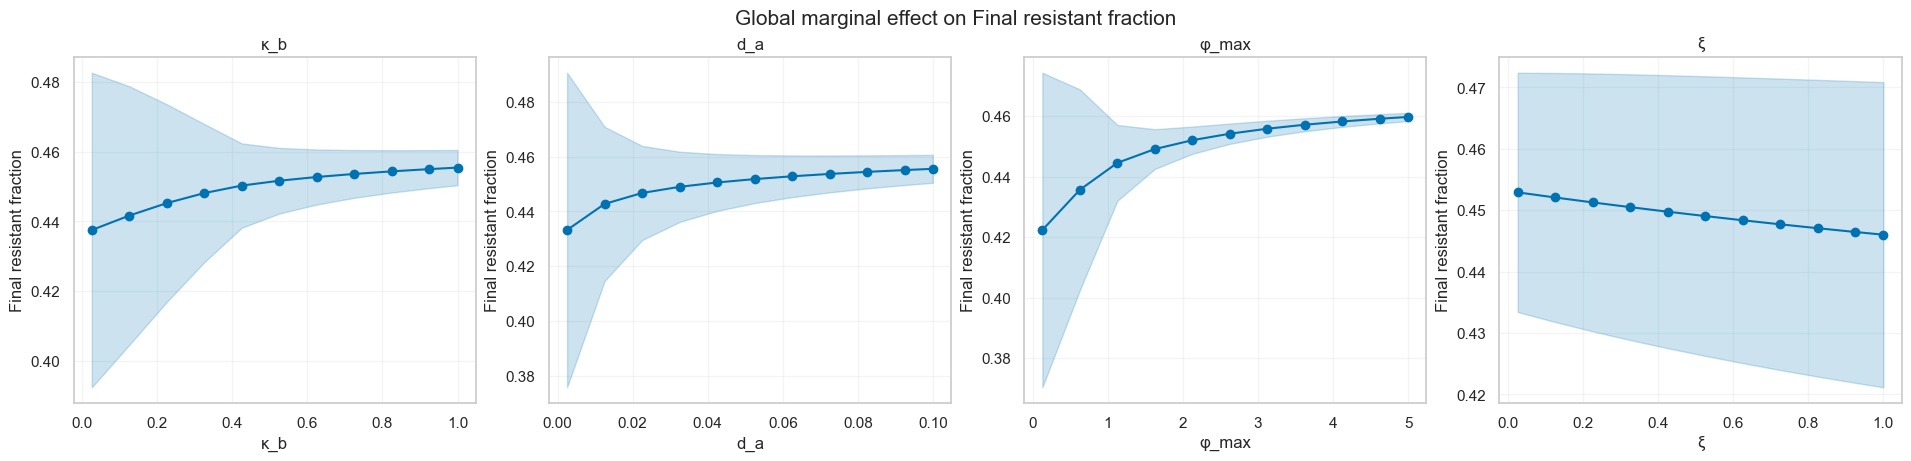

In [3]:
def binned_effect_plot(outcome, n_bins=11):
    fig, axes = plt.subplots(1,4,figsize=(19,4.5), constrained_layout=True)
    for ax, parameter in zip(axes, PARAMS):
        temp = df[[parameter, outcome]].copy()
        temp['bin'] = pd.qcut(temp[parameter], q=n_bins, duplicates='drop')
        summary = temp.groupby('bin', observed=True).agg(x=(parameter,'mean'), mean=(outcome,'mean'), sd=(outcome,'std'), n=(outcome,'size')).reset_index()
        ax.plot(summary['x'], summary['mean'], marker='o', color='#0072B2')
        ax.fill_between(summary['x'], summary['mean']-summary['sd'], summary['mean']+summary['sd'], alpha=.2, color='#0072B2')
        ax.set_xlabel(LABELS[parameter]); ax.set_ylabel(OUTCOME_LABELS.get(outcome,outcome))
        ax.set_title(LABELS[parameter]); ax.grid(alpha=.2)
    fig.suptitle(f'Global marginal effect on {OUTCOME_LABELS.get(outcome,outcome)}', fontsize=15)
    return fig

for outcome in ['peak_loss_total','t_recovery_S','t_steady_state','total_final','f_R_final']:
    binned_effect_plot(outcome); plt.show()

## 3. Standardized regression: relative importance

This estimates the effect of all four parameters simultaneously. Standardized coefficients are comparable across parameters, even though the parameters have different numerical ranges.

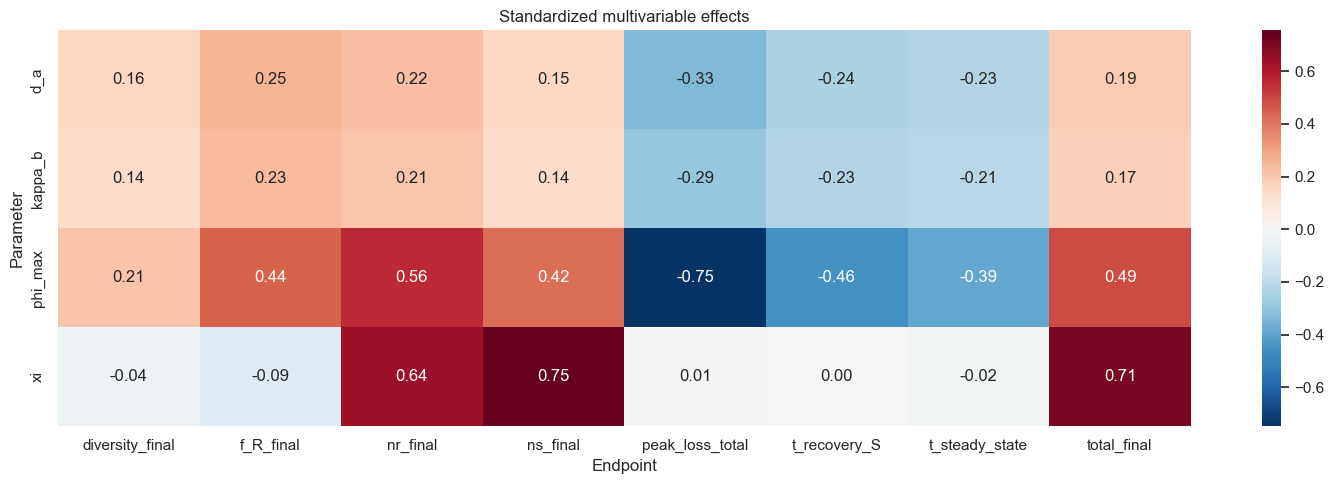

,outcome,parameter,coefficient,p_value
27,ns_final,xi,0.754320,0.0
18,peak_loss_total,phi_max,-0.746277,0.0
23,total_final,xi,0.708817,0.0
31,nr_final,xi,0.640255,0.0
30,nr_final,phi_max,0.557172,0.0
22,total_final,phi_max,0.488769,0.0
14,t_recovery_S,phi_max,-0.455231,0.0
10,f_R_final,phi_max,0.441920,0.0
26,ns_final,phi_max,0.417727,0.0
6,t_steady_state,phi_max,-0.393968,0.0


In [4]:
def standardized_formula(outcome):
    z = df.copy()
    for p in PARAMS + [outcome]:
        z[p] = (z[p] - z[p].mean()) / z[p].std()
    formula = outcome + ' ~ ' + ' + '.join(PARAMS)
    model = smf.ols(formula, data=z).fit()
    return model

coef_rows = []
for outcome in OUTCOMES:
    model = standardized_formula(outcome)
    for p in PARAMS:
        coef_rows.append({'outcome':outcome,'parameter':p,'coefficient':model.params[p],'p_value':model.pvalues[p]})
coef_df = pd.DataFrame(coef_rows)
coef_matrix = coef_df.pivot(index='parameter', columns='outcome', values='coefficient')

plt.figure(figsize=(15,5))
sns.heatmap(coef_matrix, annot=True, fmt='.2f', cmap='RdBu_r', center=0)
plt.title('Standardized multivariable effects')
plt.xlabel('Endpoint'); plt.ylabel('Parameter')
plt.tight_layout(); plt.show()
display(coef_df.sort_values('coefficient', key=abs, ascending=False).head(15))

## 4. Test parameter interactions

The interaction terms test whether the effect of one parameter depends on another. This is a better test of a relationship than visually inspecting a heatmap.

,outcome,pair,coefficient,p_value,r_squared
14,t_steady_state,d_a × φ_max,48.995793,0.000000e+00,0.316268
26,f_R_final,d_a × φ_max,-0.129395,0.000000e+00,0.392293
25,f_R_final,κ_b × φ_max,-0.011941,0.000000e+00,0.382061
23,total_final,κ_b × d_a,-4.653759,0.000000e+00,0.811313
22,total_final,φ_max × ξ,-0.350465,0.000000e+00,0.868606
21,total_final,d_a × ξ,-6.057557,0.000000e+00,0.814331
20,total_final,d_a × φ_max,-1.920160,0.000000e+00,0.825469
19,total_final,κ_b × φ_max,-0.173042,0.000000e+00,0.821992
18,total_final,κ_b × ξ,-0.558534,0.000000e+00,0.813227
17,t_steady_state,κ_b × d_a,171.823598,0.000000e+00,0.284181


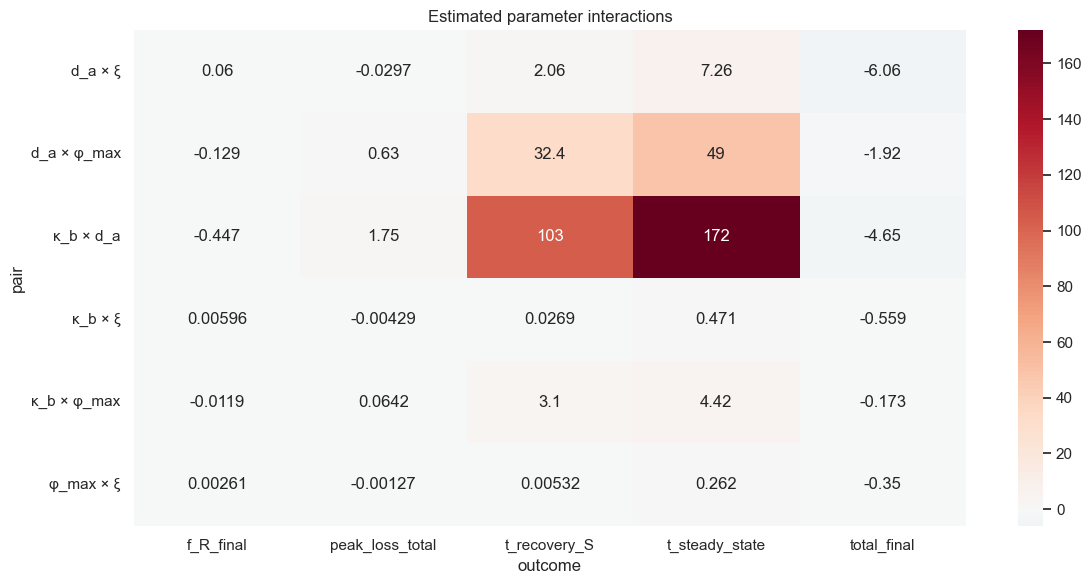

In [5]:
interaction_pairs = [('kappa_b','xi'),('kappa_b','phi_max'),('d_a','phi_max'),('d_a','xi'),('phi_max','xi'),('kappa_b','d_a')]
interaction_rows = []
for outcome in ['peak_loss_total','t_recovery_S','t_steady_state','total_final','f_R_final']:
    for p1,p2 in interaction_pairs:
        formula = f'{outcome} ~ ' + ' + '.join(PARAMS) + f' + {p1}:{p2}'
        model = smf.ols(formula, data=df).fit()
        term = f'{p1}:{p2}'
        interaction_rows.append({'outcome':outcome,'pair':f'{LABELS[p1]} × {LABELS[p2]}','coefficient':model.params[term],'p_value':model.pvalues[term],'r_squared':model.rsquared})
interactions = pd.DataFrame(interaction_rows)
display(interactions.sort_values('p_value').head(20))

interaction_matrix = interactions.pivot(index='pair', columns='outcome', values='coefficient')
plt.figure(figsize=(12,6))
sns.heatmap(interaction_matrix, annot=True, fmt='.3g', cmap='RdBu_r', center=0)
plt.title('Estimated parameter interactions')
plt.tight_layout(); plt.show()

## 5. Endpoint tradeoffs

These plots show whether fast recovery comes at the cost of a deeper crash, or whether high final resistance occurs because the whole population is small.

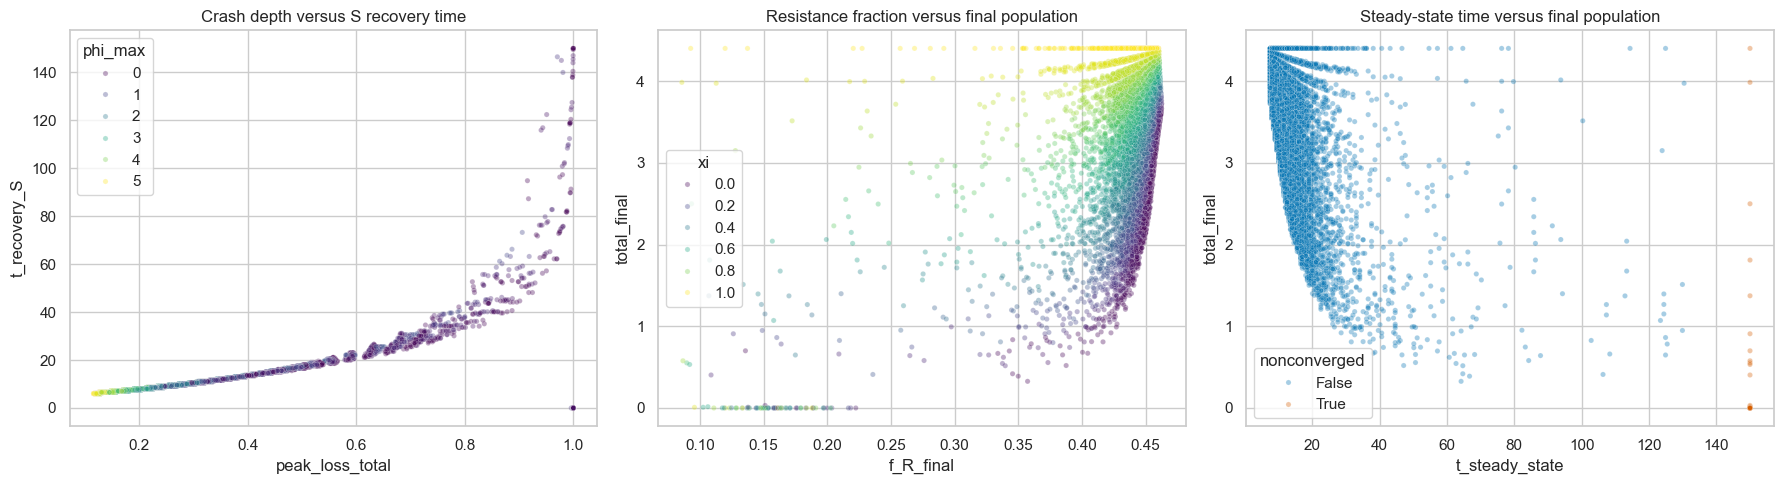

In [6]:
fig, axes = plt.subplots(1,3,figsize=(18,5))
sns.scatterplot(data=df.sample(min(30000,len(df)),random_state=1), x='peak_loss_total', y='t_recovery_S', hue='phi_max', palette='viridis', alpha=.35, s=14, ax=axes[0])
axes[0].set_title('Crash depth versus S recovery time')
sns.scatterplot(data=df.sample(min(30000,len(df)),random_state=1), x='f_R_final', y='total_final', hue='xi', palette='viridis', alpha=.35, s=14, ax=axes[1])
axes[1].set_title('Resistance fraction versus final population')
sns.scatterplot(data=df.sample(min(30000,len(df)),random_state=1), x='t_steady_state', y='total_final', hue='nonconverged', palette={False:'#0072B2',True:'#D55E00'}, alpha=.35, s=14, ax=axes[2])
axes[2].set_title('Steady-state time versus final population')
plt.tight_layout(); plt.show()

## 6. Dynamics: representative perturbation trajectories

Endpoint analysis cannot show *when* a parameter acts. These simulations show antibiotic clearance, sensitive-cell dynamics, and resistant-cell dynamics for low, baseline, and high values of each focal parameter.

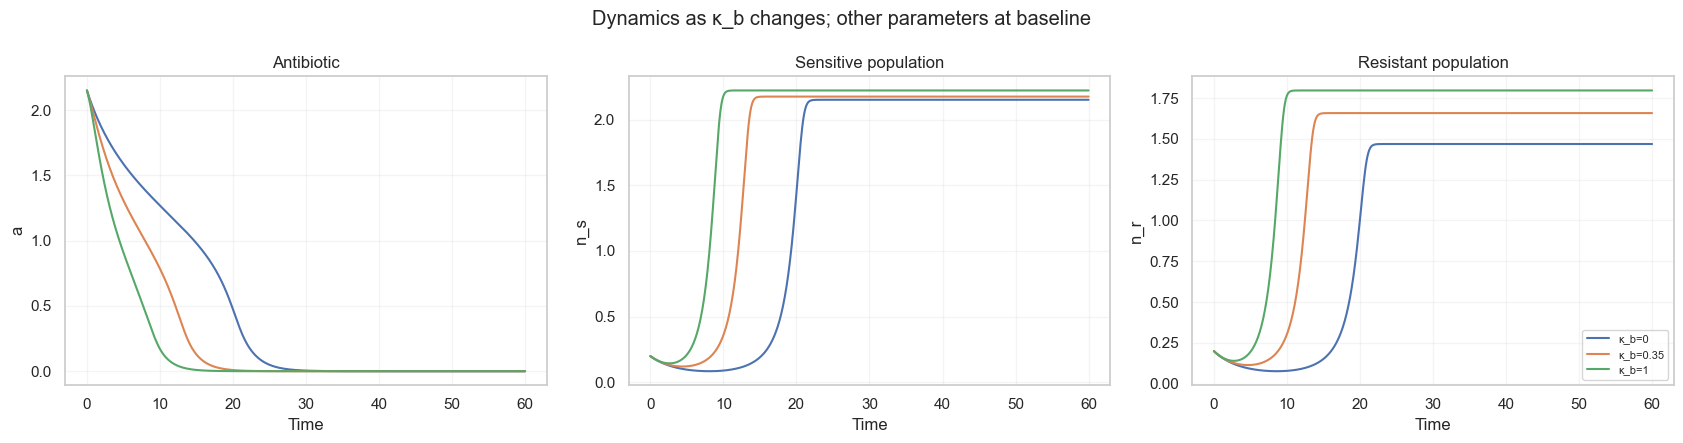

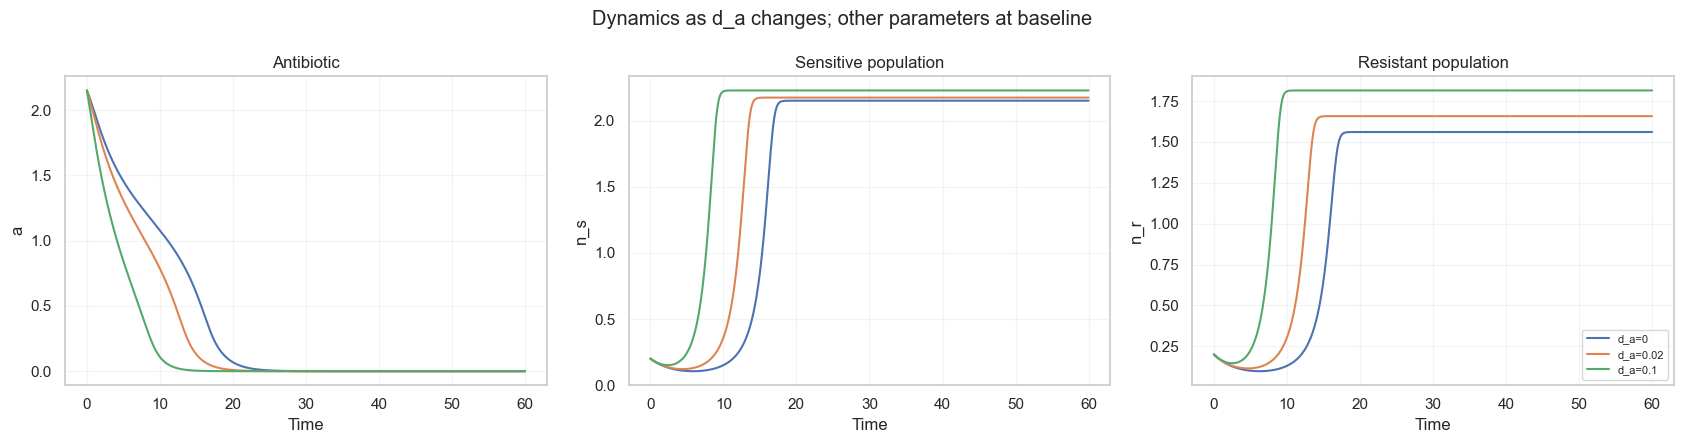

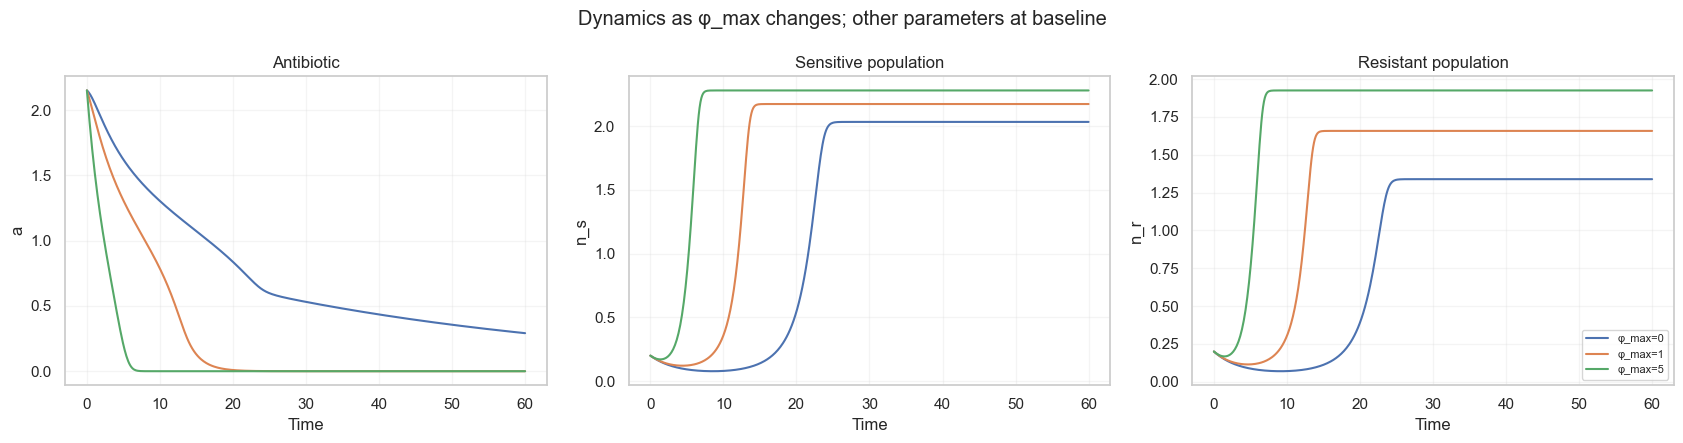

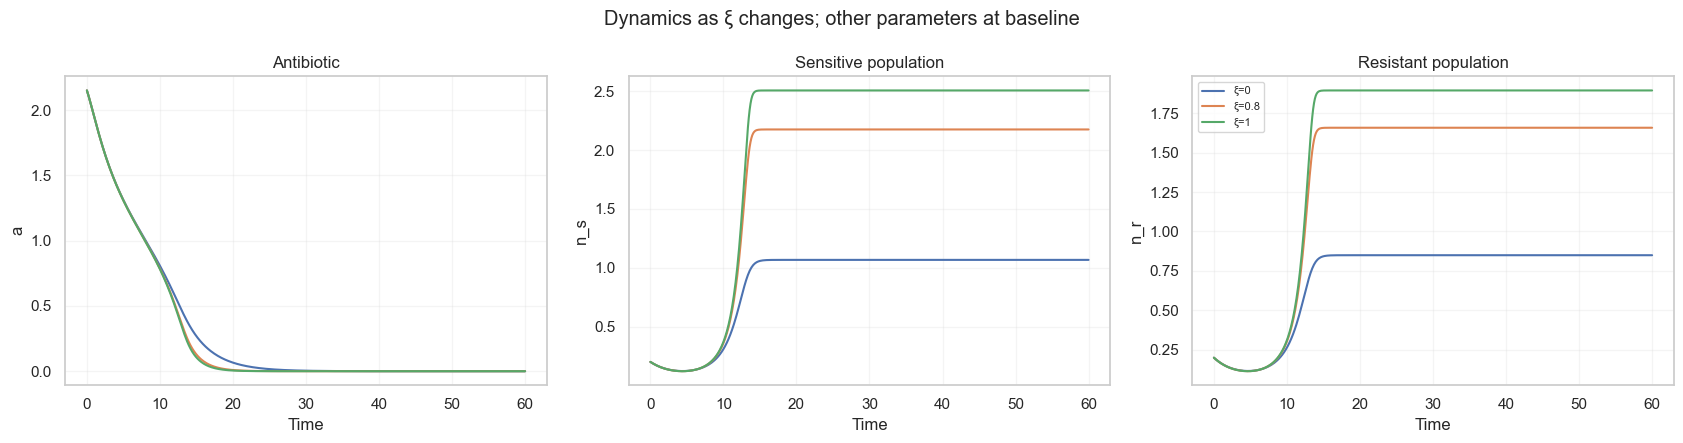

In [7]:
def representative_values(parameter):
    values = np.sort(df[parameter].unique())
    return [values[0], values[np.argmin(abs(values-BASELINE[parameter]))], values[-1]]

def timecourse_panel(parameter, t_end=60):
    values = representative_values(parameter)
    fig, axes = plt.subplots(1,3,figsize=(17,4.5),sharex=True)
    for value in values:
        p = replace(DEFAULT_PARAMS, **{parameter:float(value)})
        sol = simulate_logspace(p,a0=2.15,i_dose=10,t_span=(0,t_end),n_points=500)
        label = f'{LABELS[parameter]}={value:g}'
        axes[0].plot(sol.t,sol.a,label=label)
        axes[1].plot(sol.t,sol.ns,label=label)
        axes[2].plot(sol.t,sol.nr,label=label)
    for ax,title,ylabel in zip(axes,['Antibiotic','Sensitive population','Resistant population'],['a','n_s','n_r']):
        ax.set_title(title); ax.set_xlabel('Time'); ax.set_ylabel(ylabel); ax.grid(alpha=.2)
    axes[-1].legend(fontsize=8)
    fig.suptitle(f'Dynamics as {LABELS[parameter]} changes; other parameters at baseline')
    plt.tight_layout(); return fig

for parameter in PARAMS:
    timecourse_panel(parameter); plt.show()

## 7. Nonconvergence and collapse

Nonconvergence is reported separately from collapse. A simulation can fail to meet the steady-state criterion because populations are nearly extinct, or because populations remain substantial but change slowly.

nonconv_category
converged                                   194019
nonconverged near collapse                     282
nonconverged with substantial population       180
Name: count, dtype: int64


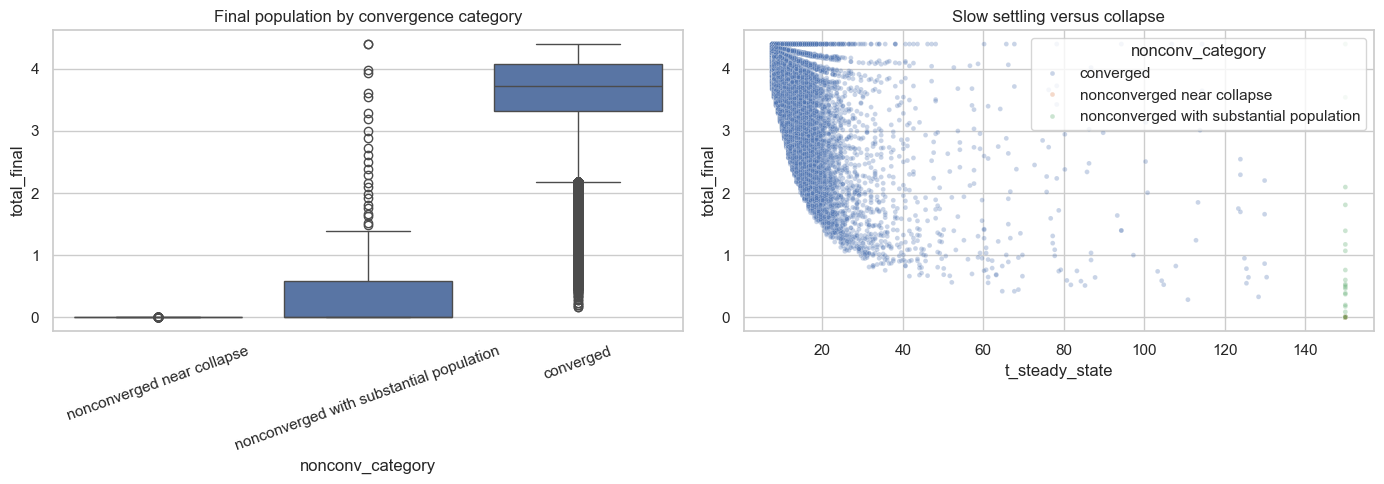

In [8]:
df['nonconv_category'] = np.select([df['nonconverged'] & df['collapsed'], df['nonconverged'] & ~df['collapsed']], ['nonconverged near collapse','nonconverged with substantial population'], default='converged')
print(df['nonconv_category'].value_counts())

fig, axes = plt.subplots(1,2,figsize=(14,5))
sns.boxplot(data=df, x='nonconv_category', y='total_final', ax=axes[0])
axes[0].tick_params(axis='x',rotation=20); axes[0].set_title('Final population by convergence category')
sns.scatterplot(data=df.sample(min(40000,len(df)),random_state=2), x='t_steady_state', y='total_final', hue='nonconv_category', alpha=.3, s=12, ax=axes[1])
axes[1].set_title('Slow settling versus collapse')
plt.tight_layout(); plt.show()

# Effects on Community Populations

In [9]:
from matplotlib.lines import Line2D

def plot_population_composition_vs_parameter(parameter, n_bins=11):
    temp = df.copy()

    # Calculate final community fractions
    temp["S_fraction_final"] = (
        temp["ns_final"] /
        (temp["ns_final"] + temp["nr_final"]).replace(0, np.nan)
    )

    temp["R_fraction_final"] = (
        temp["nr_final"] /
        (temp["ns_final"] + temp["nr_final"]).replace(0, np.nan)
    )

    # Bin parameter values so the plot shows the global trend
    temp["parameter_bin"] = pd.qcut(
        temp[parameter],
        q=n_bins,
        duplicates="drop"
    )

    summary = (
        temp.groupby("parameter_bin", observed=True)
        .agg(
            parameter_value=(parameter, "mean"),

            ns_mean=("ns_final", "mean"),
            ns_sd=("ns_final", "std"),

            nr_mean=("nr_final", "mean"),
            nr_sd=("nr_final", "std"),

            S_fraction_mean=("S_fraction_final", "mean"),
            S_fraction_sd=("S_fraction_final", "std"),

            R_fraction_mean=("R_fraction_final", "mean"),
            R_fraction_sd=("R_fraction_final", "std")
        )
        .reset_index()
    )

    fig, axes = plt.subplots(
        1, 2,
        figsize=(14, 5),
        constrained_layout=True
    )

    # Absolute populations
    ax = axes[0]

    ax.plot(
        summary["parameter_value"],
        summary["ns_mean"],
        color="tab:green",
        marker="o",
        label="Sensitive population, n_s"
    )

    ax.fill_between(
        summary["parameter_value"],
        summary["ns_mean"] - summary["ns_sd"],
        summary["ns_mean"] + summary["ns_sd"],
        color="tab:green",
        alpha=0.2
    )

    ax.plot(
        summary["parameter_value"],
        summary["nr_mean"],
        color="tab:gray",
        marker="o",
        label="Resistant population, n_r"
    )

    ax.fill_between(
        summary["parameter_value"],
        summary["nr_mean"] - summary["nr_sd"],
        summary["nr_mean"] + summary["nr_sd"],
        color="tab:gray",
        alpha=0.2
    )

    ax.set_xlabel(LABELS[parameter])
    ax.set_ylabel("Final population density")
    ax.set_title("Absolute final populations")
    ax.legend()
    ax.grid(alpha=0.2)

    # Population fractions
    ax = axes[1]

    ax.plot(
        summary["parameter_value"],
        summary["S_fraction_mean"],
        color="tab:green",
        marker="o",
        label="Sensitive fraction"
    )

    ax.fill_between(
        summary["parameter_value"],
        summary["S_fraction_mean"] - summary["S_fraction_sd"],
        summary["S_fraction_mean"] + summary["S_fraction_sd"],
        color="tab:green",
        alpha=0.2
    )

    ax.plot(
        summary["parameter_value"],
        summary["R_fraction_mean"],
        color="tab:gray",
        marker="o",
        label="Resistant fraction"
    )

    ax.fill_between(
        summary["parameter_value"],
        summary["R_fraction_mean"] - summary["R_fraction_sd"],
        summary["R_fraction_mean"] + summary["R_fraction_sd"],
        color="tab:gray",
        alpha=0.2
    )

    ax.set_xlabel(LABELS[parameter])
    ax.set_ylabel("Fraction of final community")
    ax.set_ylim(0, 1)
    ax.set_title("Final population fractions")
    ax.legend()
    ax.grid(alpha=0.2)

    fig.suptitle(
        f"Community composition as {LABELS[parameter]} increases",
        fontsize=15
    )

    return fig, axes

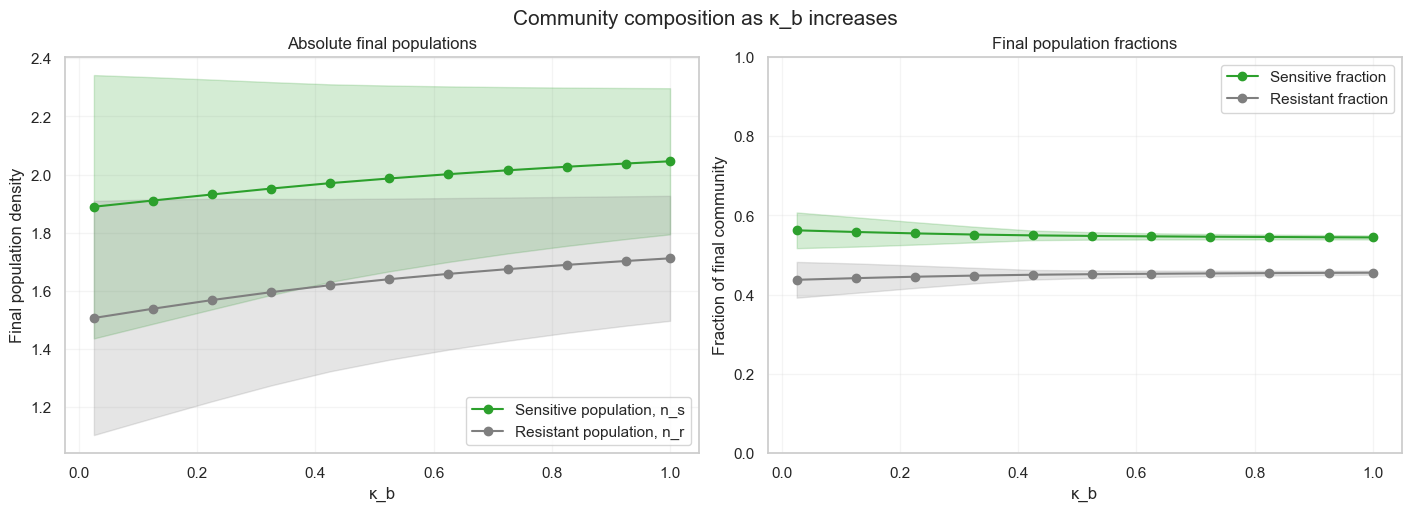

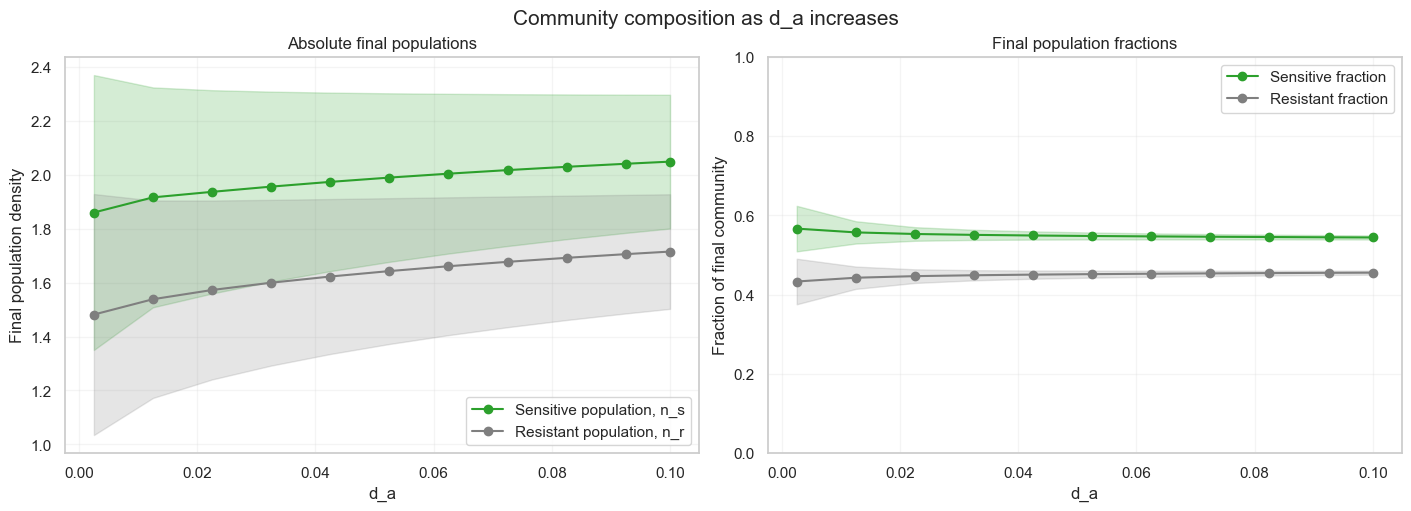

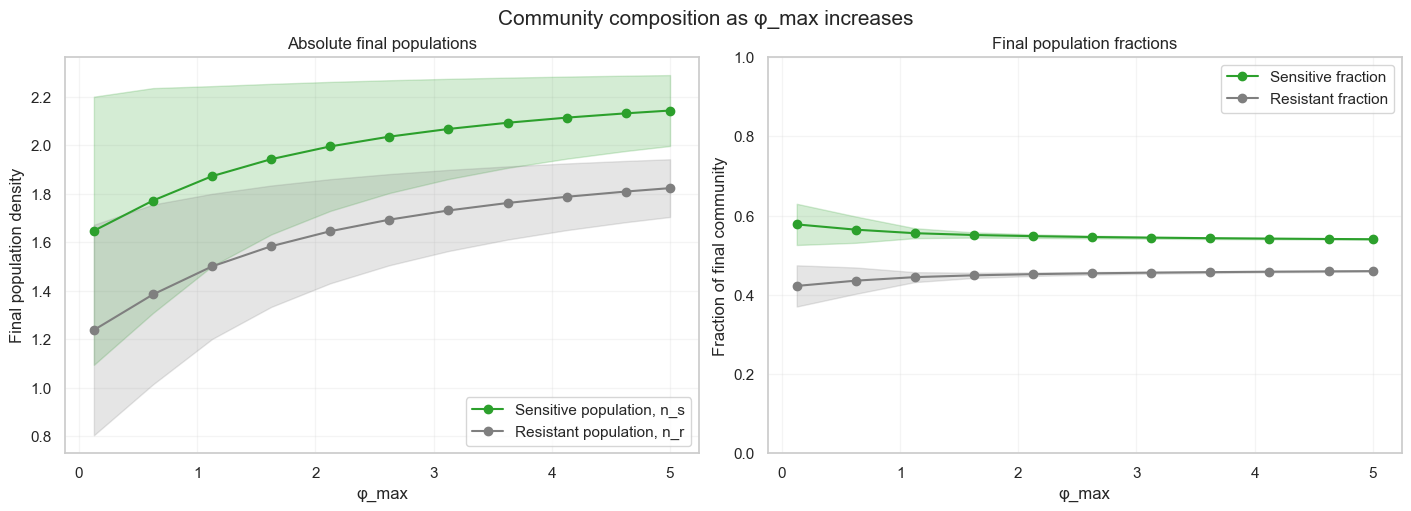

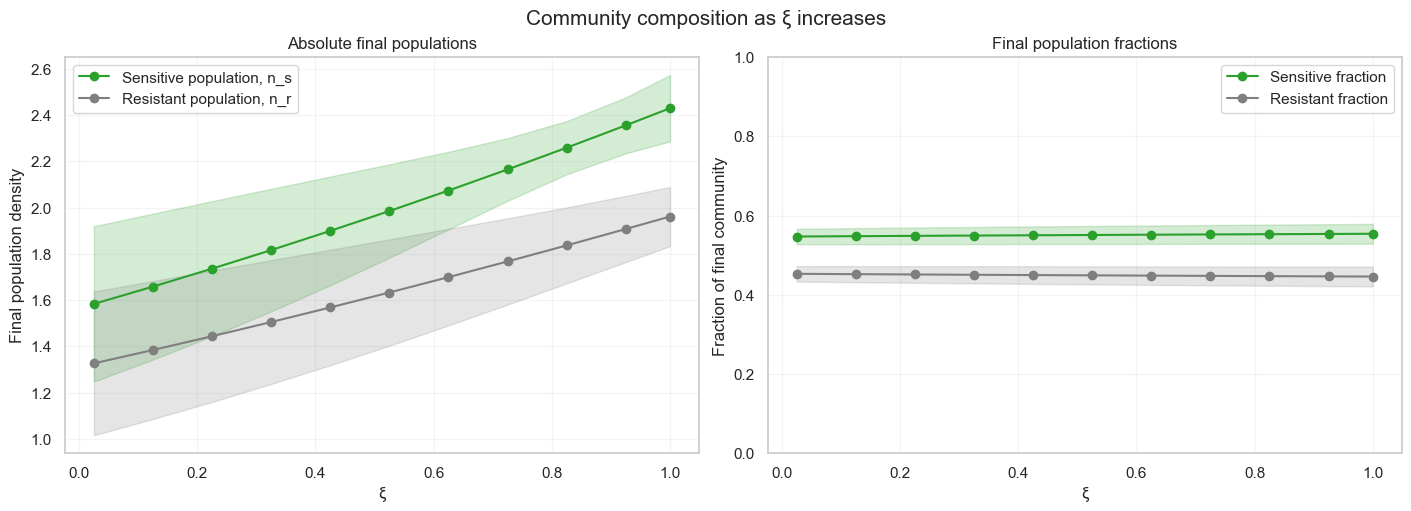

In [10]:
for parameter in PARAMS:
    plot_population_composition_vs_parameter(parameter)
    plt.show()

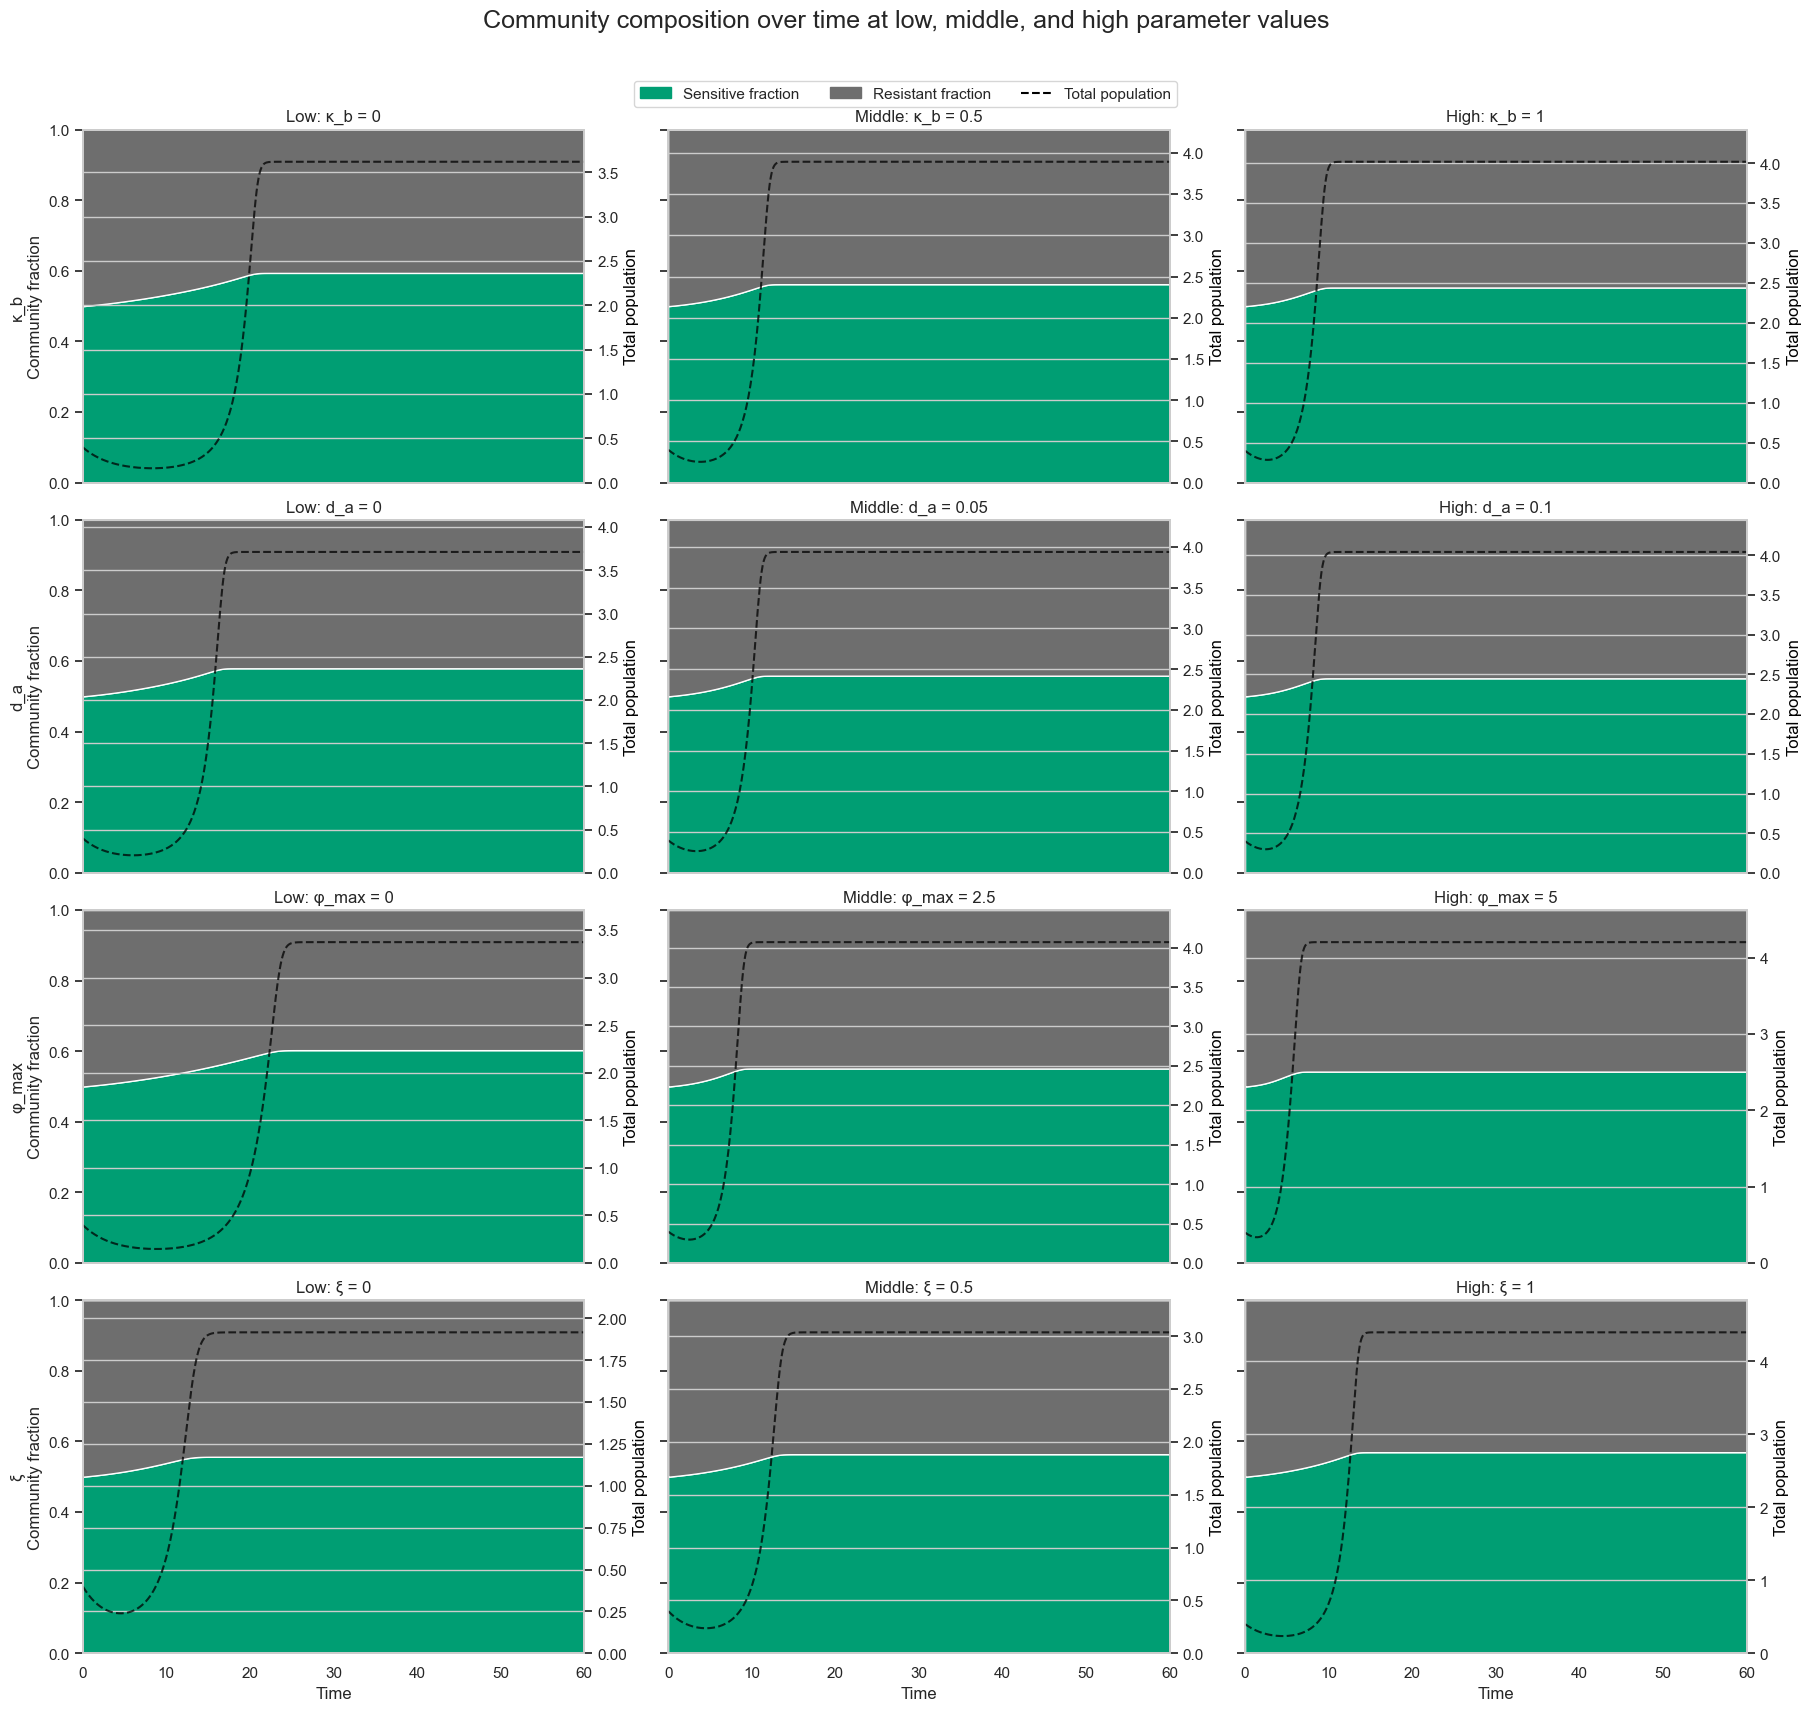

In [13]:
from dataclasses import replace

def composition_timecourse(parameter, value, t_end=60):
    """
    Simulate one parameter value and return:
    time, sensitive fraction, resistant fraction, total population
    """

    p = replace(
        DEFAULT_PARAMS,
        **{parameter: float(value)}
    )

    sol = simulate_logspace(
        p,
        a0=2.15,
        i_dose=10,
        t_span=(0, t_end),
        n_points=500
    )

    total = sol.ns + sol.nr

    sensitive_fraction = np.divide(
        sol.ns,
        total,
        out=np.zeros_like(total),
        where=total > 0
    )

    resistant_fraction = np.divide(
        sol.nr,
        total,
        out=np.zeros_like(total),
        where=total > 0
    )

    return (
        sol.t,
        sensitive_fraction,
        resistant_fraction,
        total
    )


def plot_composition_grid(t_end=60):
    fig, axes = plt.subplots(
        len(PARAMS),
        3,
        figsize=(18, 16),
        sharex=True,
        sharey=True,
        constrained_layout=True
    )

    for row, parameter in enumerate(PARAMS):

        values = np.sort(df[parameter].unique())

        selected_values = [
            values[0],
            values[len(values) // 2],
            values[-1]
        ]

        labels = ["Low", "Middle", "High"]

        for col, (value, level) in enumerate(
            zip(selected_values, labels)
        ):
            ax = axes[row, col]

            time, S_fraction, R_fraction, total = (
                composition_timecourse(
                    parameter,
                    value,
                    t_end=t_end
                )
            )

            # Stacked composition fractions
            ax.stackplot(
                time,
                S_fraction,
                R_fraction,
                colors=["#009E73", "#6E6E6E"],
                labels=["Sensitive fraction", "Resistant fraction"]
            )

            ax.set_ylim(0, 1)
            ax.set_xlim(0, t_end)

            ax.set_title(
                f"{level}: {LABELS[parameter]} = {value:g}"
            )

            ax.grid(alpha=0.2)

            # Add total population as a dashed line on a secondary axis
            ax2 = ax.twinx()
            ax2.plot(
                time,
                total,
                color="black",
                linestyle="--",
                linewidth=1.5,
                alpha=0.75
            )
            ax2.set_ylim(0, max(0.5, total.max() * 1.1))
            ax2.set_ylabel("Total population", color="black")

            if col == 0:
                ax.set_ylabel(
                    f"{LABELS[parameter]}\n"
                    "Community fraction"
                )

            if row == len(PARAMS) - 1:
                ax.set_xlabel("Time")

    # One shared legend
    handles = [
        plt.Rectangle((0, 0), 1, 1, color="#009E73"),
        plt.Rectangle((0, 0), 1, 1, color="#6E6E6E"),
        plt.Line2D(
            [0], [0],
            color="black",
            linestyle="--"
        )
    ]

    labels = [
        "Sensitive fraction",
        "Resistant fraction",
        "Total population"
    ]

    fig.legend(
        handles,
        labels,
        loc="upper center",
        ncol=3,
        bbox_to_anchor=(0.5, 1.02)
    )

    fig.suptitle(
        "Community composition over time at low, middle, and high parameter values",
        fontsize=18,
        y=1.06
    )

    return fig, axes


plot_composition_grid(t_end=60)
plt.show()

In [14]:
from dataclasses import replace

def clearance_recovery_plot(t_end=60, antibiotic_threshold=0.1):
    """
    Rows: κ_b, d_a, φ_max, ξ
    Columns:
      1. Antibiotic concentration
      2. Total population
      3. Community composition
    """

    fig, axes = plt.subplots(
        len(PARAMS),
        3,
        figsize=(18, 16),
        sharex=True,
        constrained_layout=True
    )

    clearance_summary = []

    for row, parameter in enumerate(PARAMS):

        values = np.sort(df[parameter].unique())

        selected_values = [
            values[0],
            values[len(values) // 2],
            values[-1]
        ]

        levels = ["low", "middle", "high"]

        for value, level in zip(selected_values, levels):

            p = replace(
                DEFAULT_PARAMS,
                **{parameter: float(value)}
            )

            sol = simulate_logspace(
                p,
                a0=2.15,
                i_dose=10,
                t_span=(0, t_end),
                n_points=600
            )

            total_population = sol.ns + sol.nr

            sensitive_fraction = np.divide(
                sol.ns,
                total_population,
                out=np.zeros_like(total_population),
                where=total_population > 0
            )

            resistant_fraction = np.divide(
                sol.nr,
                total_population,
                out=np.zeros_like(total_population),
                where=total_population > 0
            )

            # Time until antibiotic falls below threshold
            below_threshold = np.where(
                sol.a <= antibiotic_threshold
            )[0]

            if len(below_threshold) > 0:
                clearance_time = sol.t[below_threshold[0]]
            else:
                clearance_time = np.nan

            # Antibiotic exposure: area under antibiotic curve
            antibiotic_exposure = np.trapz(sol.a, sol.t)

            clearance_summary.append({
                "parameter": parameter,
                "level": level,
                "value": value,
                "clearance_time": clearance_time,
                "antibiotic_AUC": antibiotic_exposure,
                "minimum_total_population": total_population.min(),
                "final_total_population": total_population[-1],
                "final_sensitive_fraction": sensitive_fraction[-1],
                "final_resistant_fraction": resistant_fraction[-1]
            })

            label = f"{LABELS[parameter]} = {value:g}"

            # Column 1: antibiotic concentration
            ax = axes[row, 0]
            ax.plot(
                sol.t,
                sol.a,
                linewidth=2,
                label=label
            )
            ax.axhline(
                antibiotic_threshold,
                color="black",
                linestyle="--",
                alpha=0.6
            )
            ax.set_ylabel(
                f"{LABELS[parameter]}\nAntibiotic concentration"
            )
            ax.grid(alpha=0.2)

            # Column 2: total population
            ax = axes[row, 1]
            ax.plot(
                sol.t,
                total_population,
                linewidth=2,
                label=label
            )
            ax.set_ylabel("Total population")
            ax.grid(alpha=0.2)

            # Column 3: population composition
            ax = axes[row, 2]
            ax.stackplot(
                sol.t,
                sensitive_fraction,
                resistant_fraction,
                colors=["#009E73", "#6E6E6E"],
                alpha=0.9
            )
            ax.set_ylim(0, 1)
            ax.set_ylabel("Community fraction")
            ax.grid(alpha=0.2)

        axes[row, 0].set_title(
            "Antibiotic clearance"
            if row == 0 else ""
        )

        axes[row, 1].set_title(
            "Population crash and recovery"
            if row == 0 else ""
        )

        axes[row, 2].set_title(
            "Community composition"
            if row == 0 else ""
        )

    for ax in axes[-1, :]:
        ax.set_xlabel("Time")

    legend_handles = [
        plt.Line2D(
            [0], [0],
            color="#0072B2",
            linewidth=2,
            label="Low / middle / high parameter values"
        ),
        plt.Rectangle(
            (0, 0), 1, 1,
            color="#009E73",
            label="Sensitive fraction"
        ),
        plt.Rectangle(
            (0, 0), 1, 1,
            color="#6E6E6E",
            label="Resistant fraction"
        ),
        plt.Line2D(
            [0], [0],
            color="black",
            linestyle="--",
            label=f"Antibiotic threshold = {antibiotic_threshold}"
        )
    ]

    fig.legend(
        handles=legend_handles,
        loc="upper center",
        ncol=4,
        bbox_to_anchor=(0.5, 1.02)
    )

    fig.suptitle(
        "Antibiotic clearance, population recovery, and community composition",
        fontsize=18,
        y=1.06
    )

    plt.show()

    return pd.DataFrame(clearance_summary)

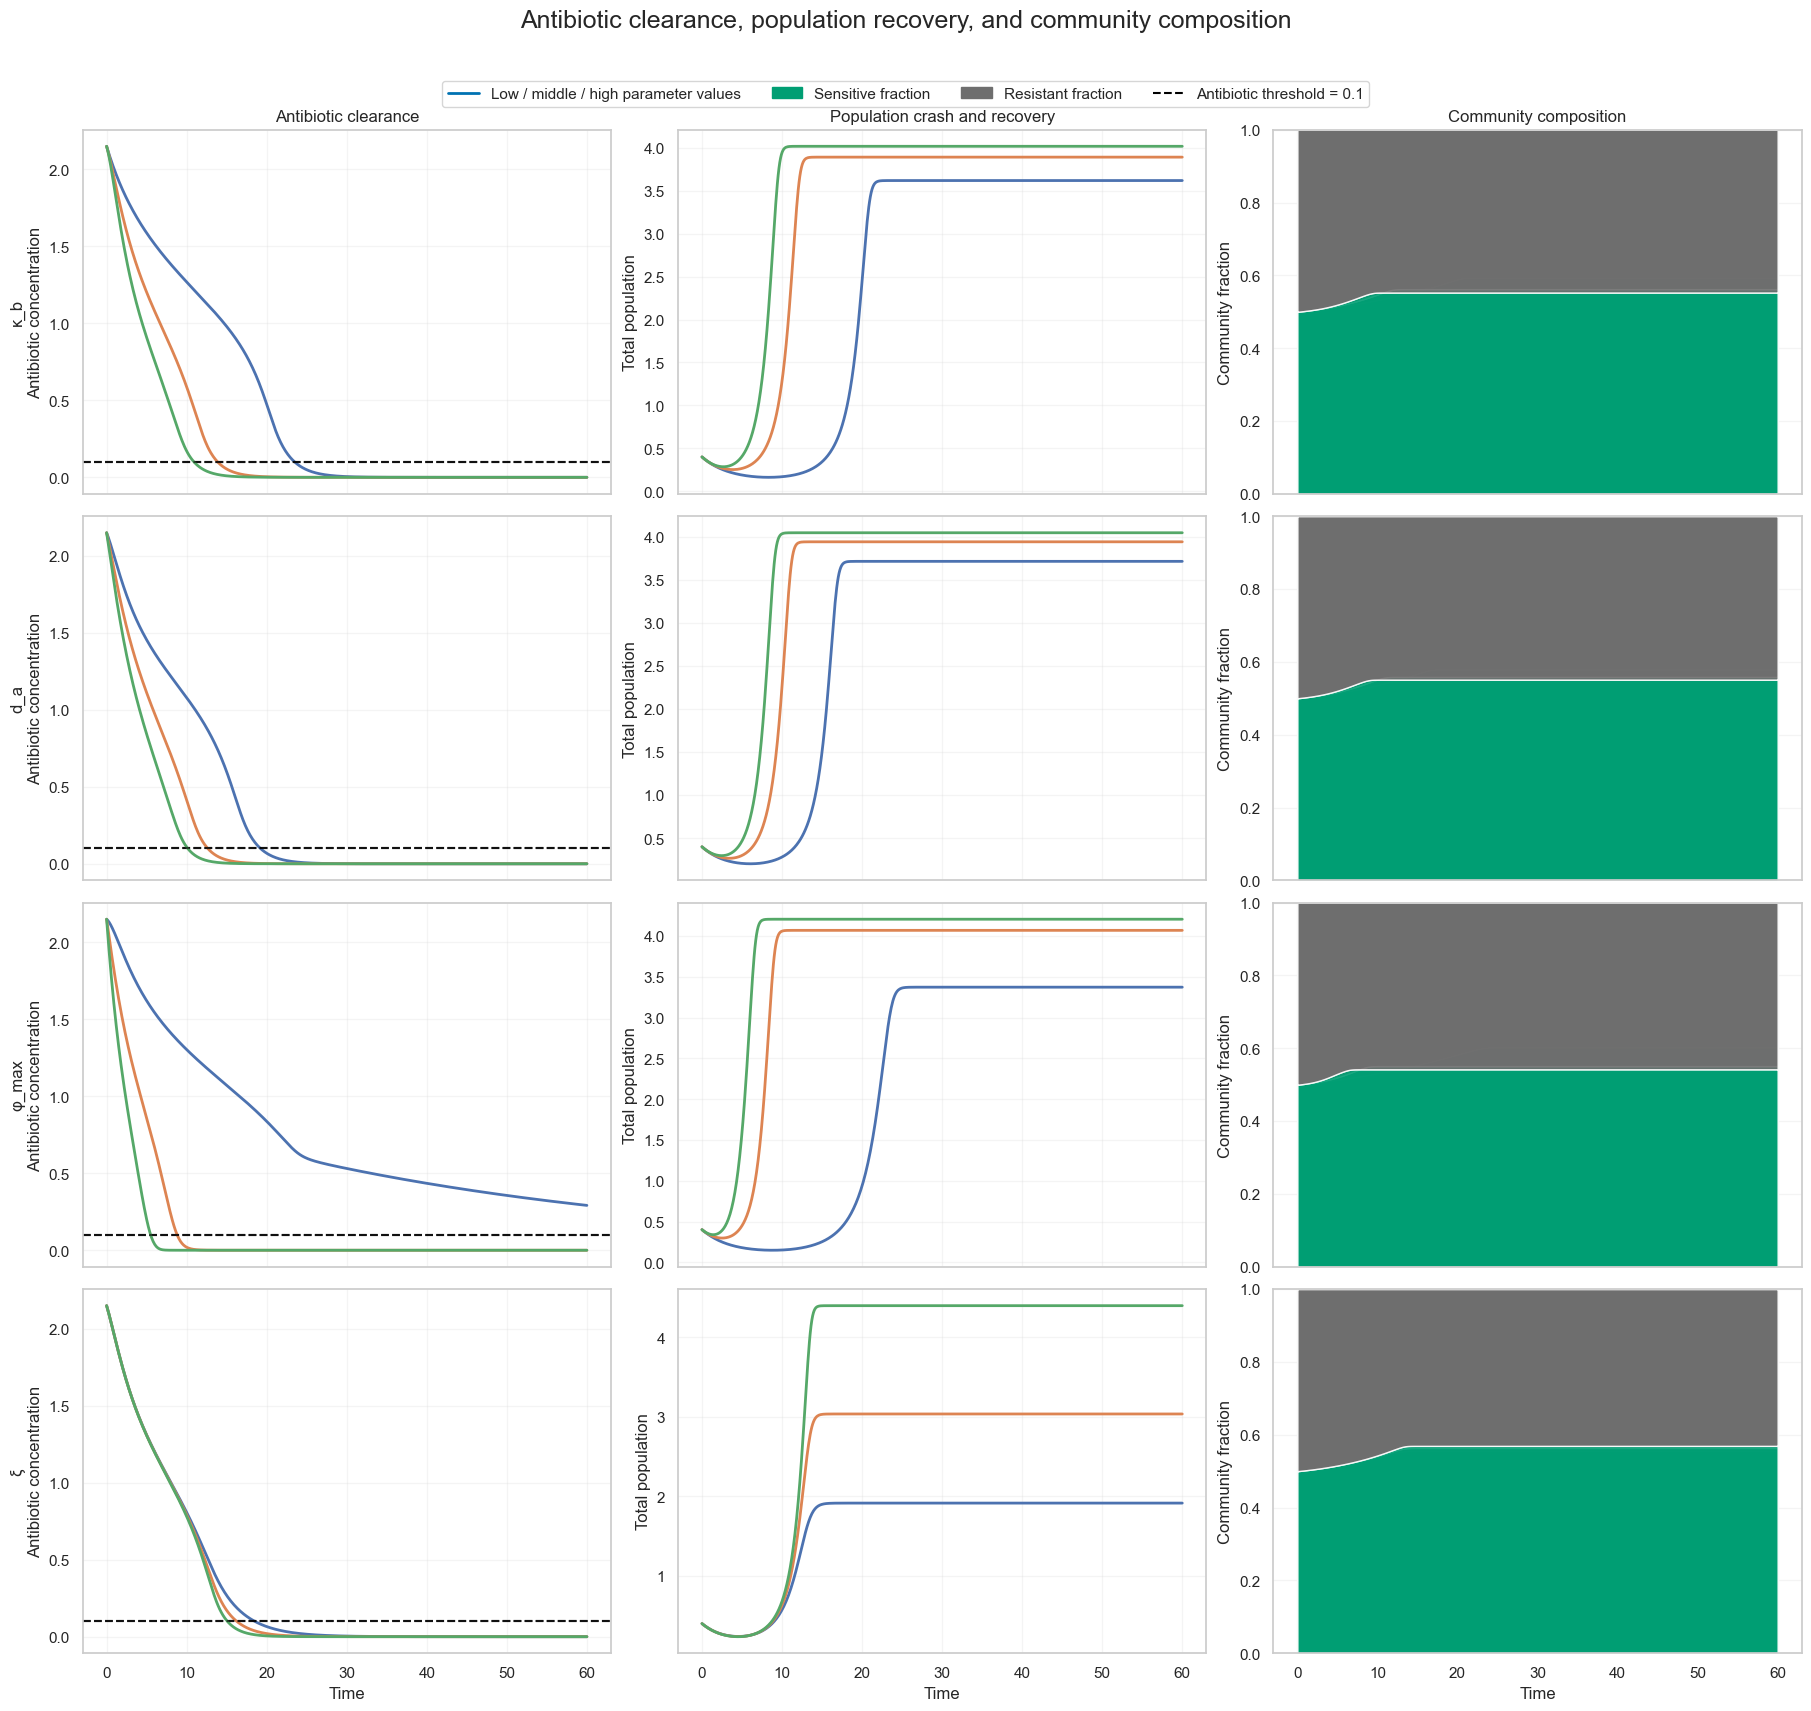

,parameter,level,value,clearance_time,antibiotic_AUC,minimum_total_population,final_total_population,final_sensitive_fraction,final_resistant_fraction
0,kappa_b,low,0.00,23.539232,26.797522,0.162604,3.618883,0.594249,0.405751
1,kappa_b,middle,0.50,13.923205,14.027649,0.252714,3.891517,0.562258,0.437742
2,kappa_b,high,1.00,10.918197,10.247830,0.285643,4.017719,0.552894,0.447106
3,d_a,low,0.00,19.232053,20.953486,0.203215,3.711940,0.579545,0.420455
4,d_a,middle,0.05,12.721202,12.496388,0.266687,3.938618,0.558574,0.441426
5,d_a,high,0.10,10.217028,9.415643,0.297534,4.043638,0.551156,0.448844
6,phi_max,low,0.00,NaN,45.660980,0.147994,3.373051,0.603096,0.396904
7,phi_max,middle,2.50,8.814691,8.951559,0.297196,4.069611,0.551113,0.448887
8,phi_max,high,5.00,5.509182,5.215031,0.338508,4.206101,0.542346,0.457654
9,xi,low,0.00,18.530885,17.294192,0.238270,1.916321,0.556612,0.443388


In [15]:
clearance_summary = clearance_recovery_plot(
    t_end=60,
    antibiotic_threshold=0.1
)

display(clearance_summary)

In [19]:
from dataclasses import replace
from matplotlib.lines import Line2D
from matplotlib.patches import Patch


def clearance_recovery_plot(
    t_end=60,
    antibiotic_threshold=0.1
):
    """
    Rows: κ_b, d_a, φ_max, ξ
    Columns:
      1. Antibiotic concentration
      2. Total population density
      3. Community composition

    All model quantities are dimensionless unless physical units
    are explicitly assigned elsewhere.
    """

    fig, axes = plt.subplots(
        len(PARAMS),
        3,
        figsize=(20, 17),
        sharex=True,
        constrained_layout=True
    )

    clearance_summary = []

    colors = [
        "#0072B2",  # low
        "#E69F00",  # middle
        "#D55E00"   # high
    ]

    for row, parameter in enumerate(PARAMS):

        values = np.sort(df[parameter].unique())

        selected_values = [
            values[0],
            values[len(values) // 2],
            values[-1]
        ]

        levels = ["low", "middle", "high"]

        row_handles = []

        for value, level, color in zip(
            selected_values,
            levels,
            colors
        ):

            p = replace(
                DEFAULT_PARAMS,
                **{parameter: float(value)}
            )

            sol = simulate_logspace(
                p,
                a0=2.15,
                i_dose=10,
                t_span=(0, t_end),
                n_points=600
            )

            total_population = sol.ns + sol.nr

            sensitive_fraction = np.divide(
                sol.ns,
                total_population,
                out=np.zeros_like(total_population),
                where=total_population > 0
            )

            resistant_fraction = np.divide(
                sol.nr,
                total_population,
                out=np.zeros_like(total_population),
                where=total_population > 0
            )

            below_threshold = np.where(
                sol.a <= antibiotic_threshold
            )[0]

            if len(below_threshold) > 0:
                clearance_time = sol.t[below_threshold[0]]
            else:
                clearance_time = np.nan

            antibiotic_exposure = np.trapz(
                sol.a,
                sol.t
            )

            clearance_summary.append({
                "parameter": parameter,
                "level": level,
                "value": value,
                "clearance_time": clearance_time,
                "antibiotic_AUC": antibiotic_exposure,
                "minimum_total_population": total_population.min(),
                "final_total_population": total_population[-1],
                "final_sensitive_fraction": sensitive_fraction[-1],
                "final_resistant_fraction": resistant_fraction[-1]
            })

            label = (
                f"{level.capitalize()}: "
                f"{LABELS[parameter]} = {value:g}"
            )

            # Legend handle for this parameter value
            row_handles.append(
                Line2D(
                    [0],
                    [0],
                    color=color,
                    linewidth=2.5,
                    label=label
                )
            )

            # Antibiotic concentration
            ax = axes[row, 0]

            ax.plot(
                sol.t,
                sol.a,
                color=color,
                linewidth=2.2
            )

            # Total population
            ax = axes[row, 1]

            ax.plot(
                sol.t,
                total_population,
                color=color,
                linewidth=2.2
            )

            # Community composition
            ax = axes[row, 2]

            # Only stackplot once per parameter row
            if level == "low":
                ax.stackplot(
                    sol.t,
                    sensitive_fraction,
                    resistant_fraction,
                    colors=["#009E73", "#6E6E6E"],
                    alpha=0.9
                )
            else:
                # Overlay composition boundaries for middle/high cases
                ax.plot(
                    sol.t,
                    sensitive_fraction,
                    color=color,
                    linewidth=1.8,
                    linestyle="-"
                )

                ax.plot(
                    sol.t,
                    sensitive_fraction + resistant_fraction,
                    color=color,
                    linewidth=1.8,
                    linestyle="--"
                )

        # Add antibiotic threshold to each row
        axes[row, 0].axhline(
            antibiotic_threshold,
            color="black",
            linestyle="--",
            linewidth=1.2,
            alpha=0.7
        )

        # Row-specific legends with explicit parameter values
        axes[row, 0].legend(
            handles=row_handles,
            title=f"Perturbed {LABELS[parameter]}",
            fontsize=8,
            title_fontsize=9,
            loc="best"
        )

        axes[row, 1].legend(
            handles=row_handles,
            title=f"Perturbed {LABELS[parameter]}",
            fontsize=8,
            title_fontsize=9,
            loc="best"
        )

        # Axis labels with units
        axes[row, 0].set_ylabel(
            f"{LABELS[parameter]}\n"
            "Antibiotic concentration, a\n"
            "(dimensionless)"
        )

        axes[row, 1].set_ylabel(
            "Total population density\n"
            "(dimensionless)"
        )

        axes[row, 2].set_ylabel(
            "Community fraction\n"
            "(0–1)"
        )

        for ax in axes[row, :]:
            ax.grid(alpha=0.2)

        axes[row, 2].set_ylim(0, 1)

    # Column titles
    axes[0, 0].set_title(
        "Antibiotic clearance",
        fontsize=13
    )

    axes[0, 1].set_title(
        "Population crash and recovery",
        fontsize=13
    )

    axes[0, 2].set_title(
        "Community composition",
        fontsize=13
    )

    # Shared x-axis labels
    for ax in axes[-1, :]:
        ax.set_xlabel(
            "Time, τ (dimensionless)"
        )

    # Legend for composition panel
    composition_handles = [
        Patch(
            facecolor="#009E73",
            label="Sensitive fraction"
        ),
        Patch(
            facecolor="#6E6E6E",
            label="Resistant fraction"
        ),
        Line2D(
            [0],
            [0],
            color="black",
            linestyle="--",
            label=(
                f"Antibiotic threshold = "
                f"{antibiotic_threshold:g}"
            )
        )
    ]

    fig.legend(
        handles=composition_handles,
        loc="upper center",
        ncol=3,
        bbox_to_anchor=(0.5, 1.02),
        title="Community composition and clearance threshold"
    )

    fig.suptitle(
        "Antibiotic clearance, population recovery, "
        "and community composition",
        fontsize=18,
        y=1.07
    )

    plt.show()

    return pd.DataFrame(clearance_summary)

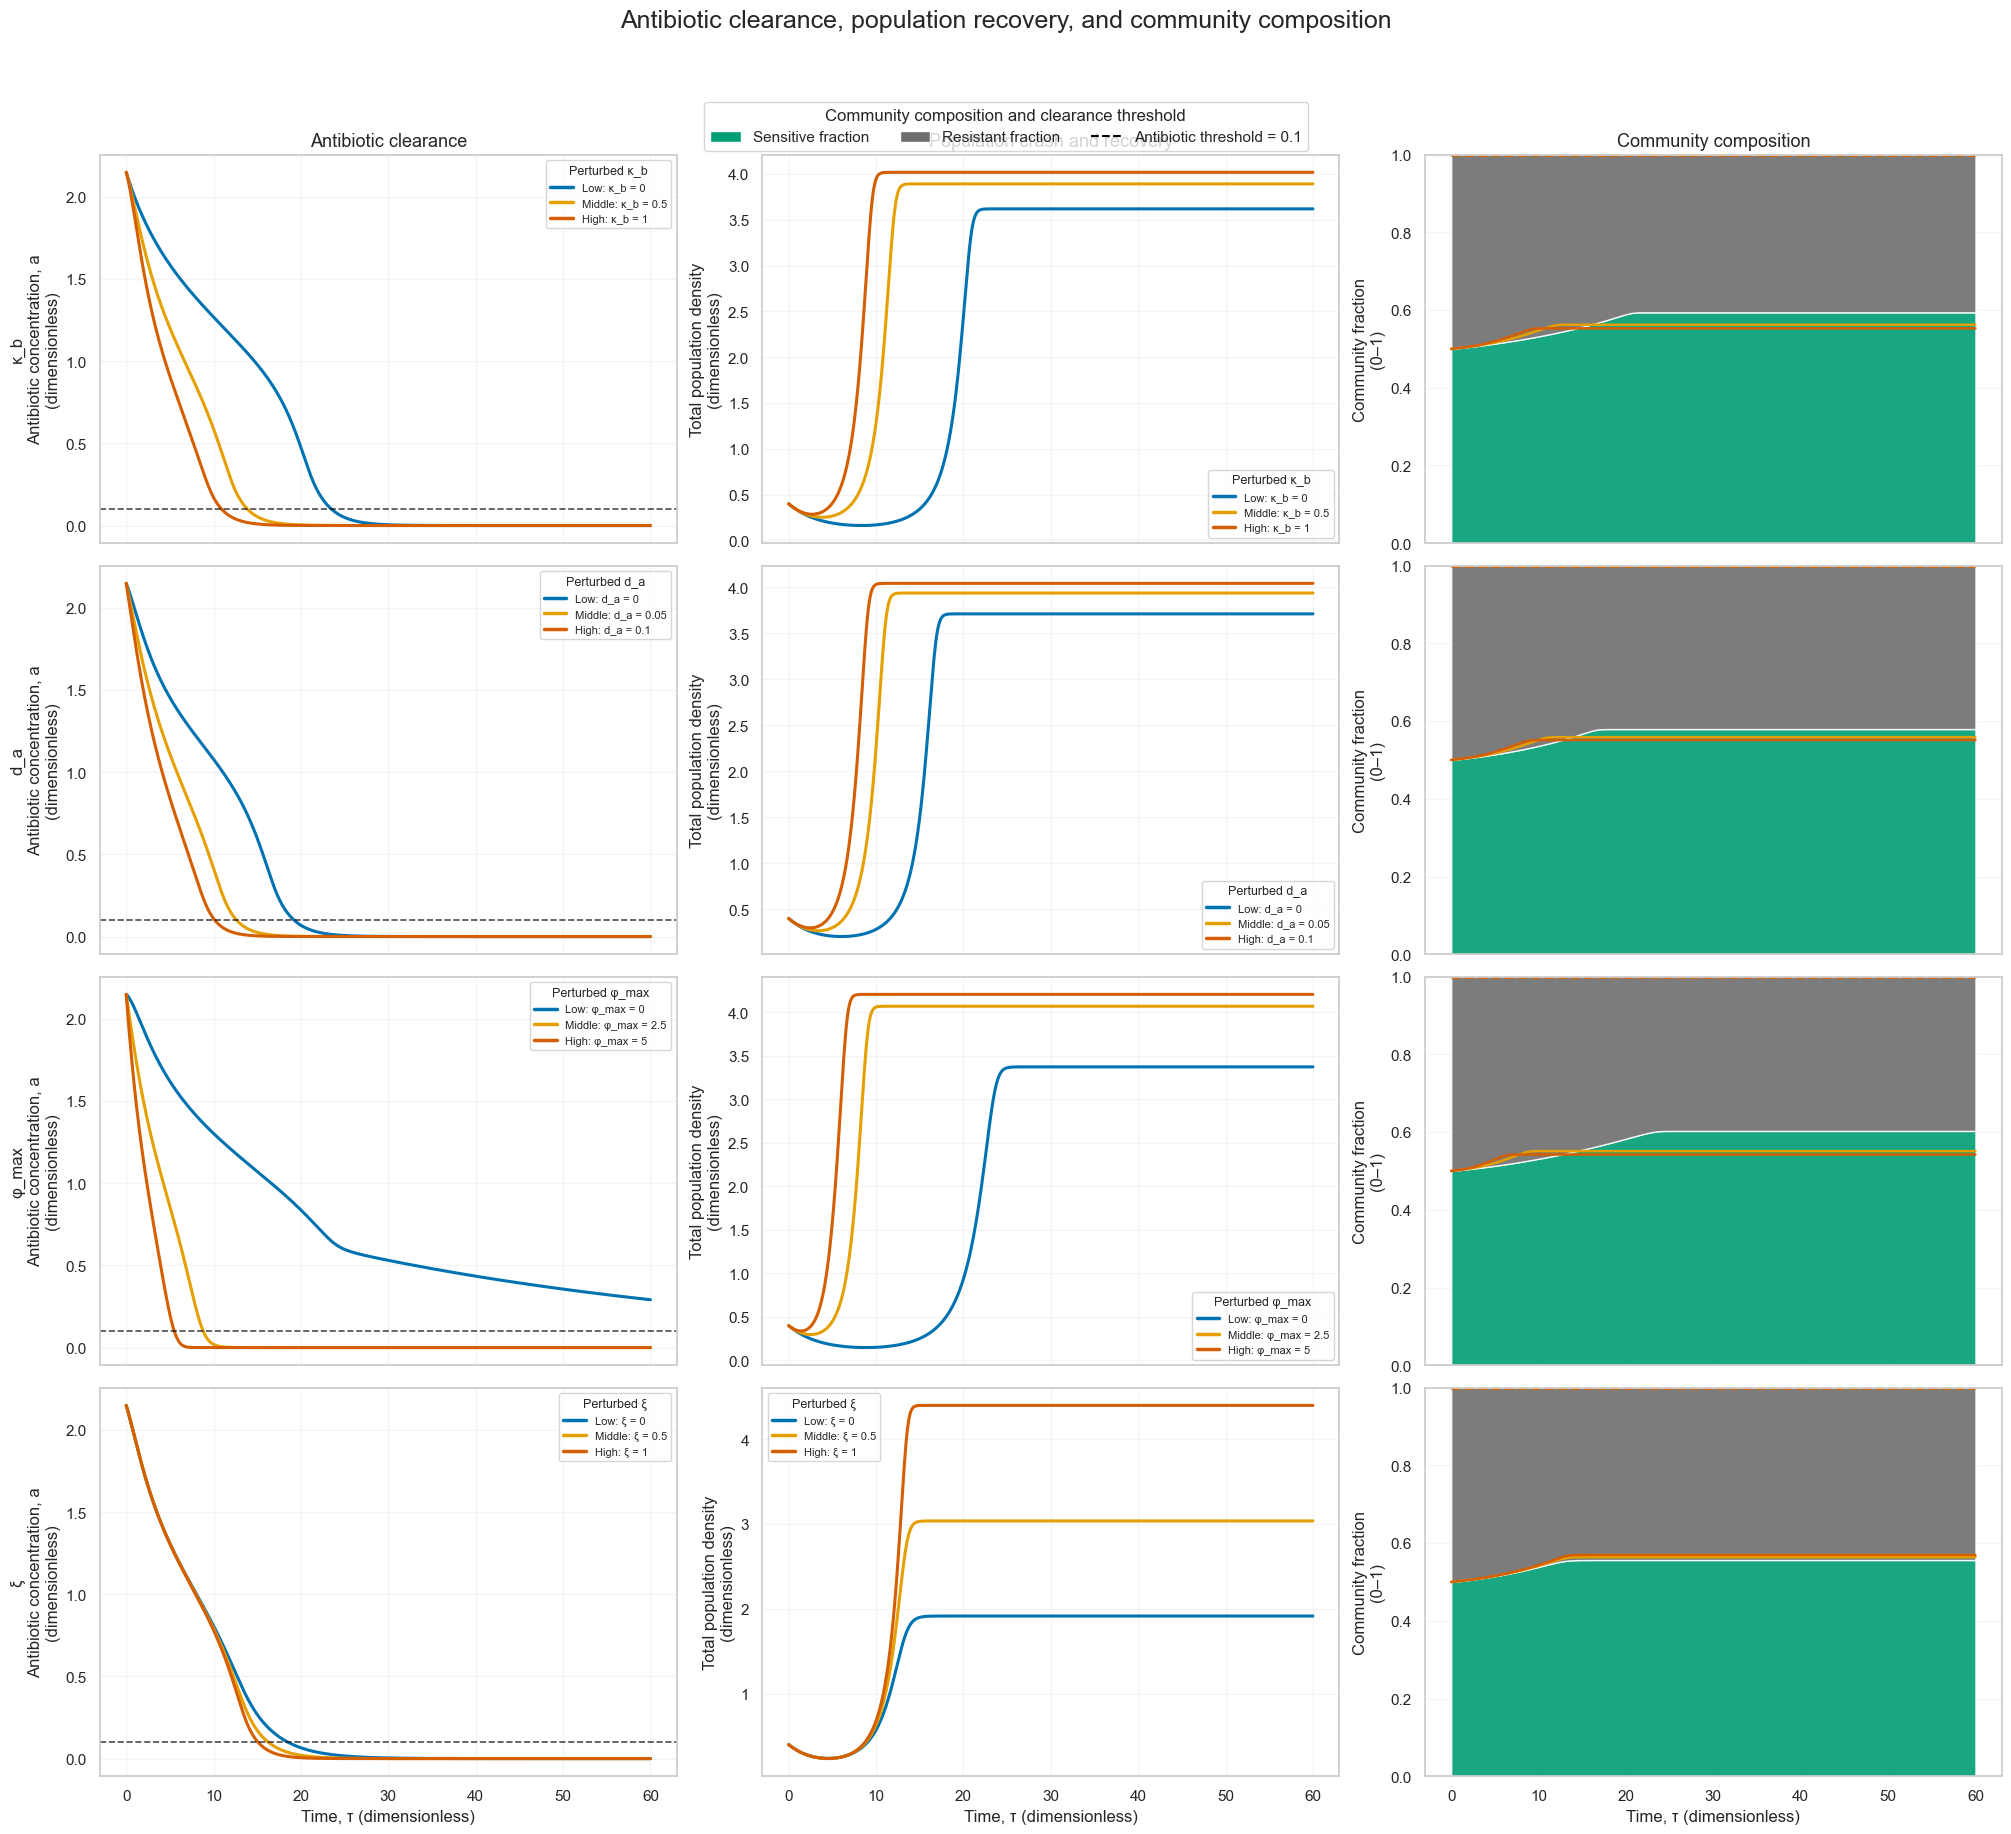

,parameter,level,value,clearance_time,antibiotic_AUC,minimum_total_population,final_total_population,final_sensitive_fraction,final_resistant_fraction
0,kappa_b,low,0.00,23.539232,26.797522,0.162604,3.618883,0.594249,0.405751
1,kappa_b,middle,0.50,13.923205,14.027649,0.252714,3.891517,0.562258,0.437742
2,kappa_b,high,1.00,10.918197,10.247830,0.285643,4.017719,0.552894,0.447106
3,d_a,low,0.00,19.232053,20.953486,0.203215,3.711940,0.579545,0.420455
4,d_a,middle,0.05,12.721202,12.496388,0.266687,3.938618,0.558574,0.441426
5,d_a,high,0.10,10.217028,9.415643,0.297534,4.043638,0.551156,0.448844
6,phi_max,low,0.00,NaN,45.660980,0.147994,3.373051,0.603096,0.396904
7,phi_max,middle,2.50,8.814691,8.951559,0.297196,4.069611,0.551113,0.448887
8,phi_max,high,5.00,5.509182,5.215031,0.338508,4.206101,0.542346,0.457654
9,xi,low,0.00,18.530885,17.294192,0.238270,1.916321,0.556612,0.443388


In [20]:
clearance_summary = clearance_recovery_plot(
    t_end=60,
    antibiotic_threshold=0.1
)

display(clearance_summary)

## Recommended interpretation

Use the standardized effects and binned marginal plots to identify the dominant perturbations. Use interaction terms to test whether parameters work together. Use time courses to identify whether a parameter changes antibiotic clearance, crash depth, or regrowth. Use final resistant fraction only together with final population size, because a high fraction can occur when both populations are nearly absent.